# ART rank CUSUM for quantile breakpoints: two trial scores

This experiment follows the [shared discussion](https://chatgpt.com/s/t_6aed779cf77c8191b73d79e52e5de90f) and Cui et al., [ART](https://doi.org/10.1093/jrsssb/qkag037), Sections 2.3 and 3.1–3.2 ([local PDF](../../articles/qkag037.pdf)).

We import our synthetic-data generator, fit a **straight-line conditional quantile**, construct two scores, and apply global and local **rank CUSUM**. We then plot the permutation distributions of the test statistics and the empirical distributions of their p-values under no slope changes and two slope changes. Only these CUSUM experiments are implemented: no likelihood aggregation, recursive segmentation, or post-selection breakpoint confidence intervals.

**Two scores being tried:** signed residual $e_i=Y_i-\widehat q_\tau(X_i)$ and indicator $b_i=\mathbf1\{Y_i\leq\widehat q_\tau(X_i)\}$. Neither is assumed to deliver a valid quantile-breakpoint test merely because it is ranked.

The scan order is **increasing X**, not the generator's random row order and not score order. The original ART model uses a sequence with homogeneous segments; a continuous slope kink is an adaptation to investigate, not an abrupt distributional jump covered automatically by that model.

In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import replace
from itertools import permutations
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.stats import binomtest
from IPython.display import display

# Works when Jupyter starts either in this folder or at the repository root.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "synthetic_data" / "generator.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from synthetic_data import QuantileDataGenerator

N, TAU, SEED = 300, 0.8, 2026
B, REPLICATIONS, ALPHA = 1999, 300, 0.05  # Increase replications for a more precise size/power study.
FIT_TOL = 1e-9  # Treat numerical LP interpolation residuals as zero.
model = QuantileDataGenerator(n=N, tau=TAU, breakpoints=(0.4, 0.7),
    slope_changes=(-0.9, 0.9), sigma=(0.4, 0.6), df=8,
    near_share=0.05, half_width=0.05, seed=SEED)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
print(f"Course Python: {sys.version.split()[0]} | {sys.executable}")

Course Python: 3.14.6 | /Users/feng/envThesis/bin/python


## 1. Generate a complete DataFrame, then fit once

The generator supplies $Q_\tau(Y\mid X=x)=m(x)$ exactly. Under the simulated null, set all slope changes to zero while retaining the same X design, noise, and windows. Under the alternative, keep the two bends. **The fitted baseline has no knots**, otherwise fitting the true bends could remove the signal we want to examine.

The LP below minimizes the quantile check loss for intercept and slope. Its objective is invariant to row order. Canonically ordering its inputs also makes the numerical choice of solution reproducible when minimizers are nonunique. This addresses score construction symmetry; it does **not** establish exchangeability after ordering by X.

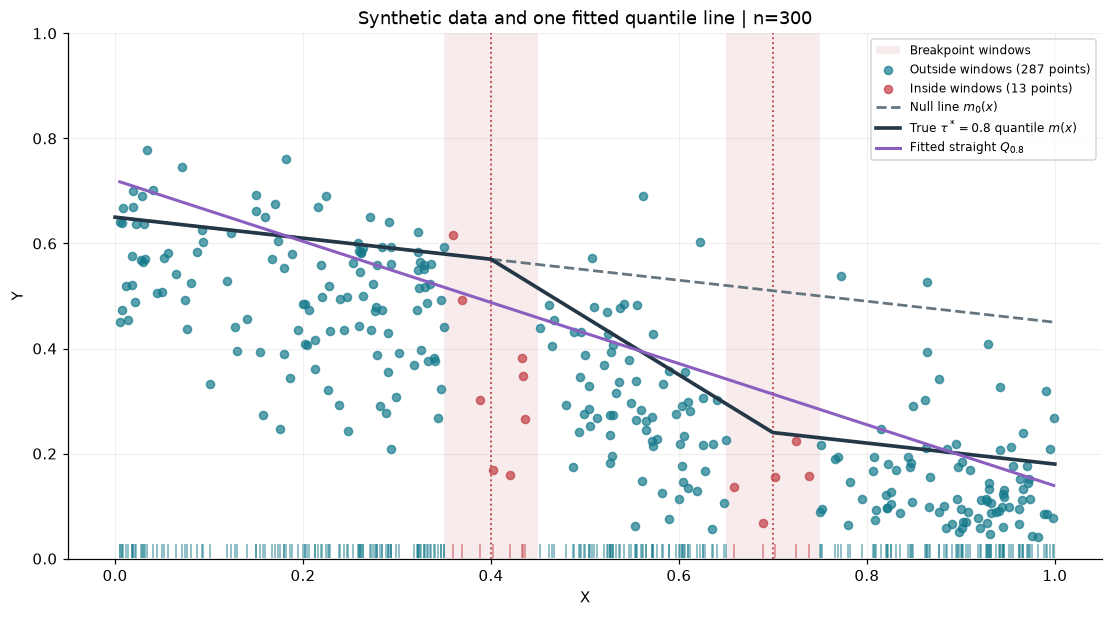

Fitted intercept=0.7203, slope=-0.5817; all 300 rows stored in data.


,draw_id,X,Y,m_true,m_null,sigma,Z,near_breakpoint,q_fitted,residual_fitted,indicator_fitted,residual_known,indicator_known
0,275,0.0050,0.6416,0.6490,0.6490,0.4010,-0.0807,False,0.7174,-0.0758,1,-0.0074,1
1,103,0.0055,0.4498,0.6489,0.6489,0.4011,-2.0340,False,0.7171,-0.2674,1,-0.1991,1
2,182,0.0074,0.4742,0.6485,0.6485,0.4015,-1.7831,False,0.7160,-0.2418,1,-0.1743,1
3,92,0.0074,0.6389,0.6485,0.6485,0.4015,-0.1040,False,0.7160,-0.0771,1,-0.0096,1
4,53,0.0087,0.6671,0.6483,0.6483,0.4017,0.2086,False,0.7152,-0.0481,1,0.0189,0
5,105,0.0111,0.5194,0.6478,0.6478,0.4022,-1.3219,False,0.7138,-0.1945,1,-0.1284,1
6,246,0.0141,0.4551,0.6472,0.6472,0.4028,-1.9534,False,0.7121,-0.2571,1,-0.1921,1
7,160,0.0177,0.5214,0.6465,0.6465,0.4035,-1.2833,False,0.7100,-0.1886,1,-0.1251,1
8,219,0.0178,0.5765,0.6464,0.6464,0.4036,-0.7310,False,0.7100,-0.1335,1,-0.0699,1
9,6,0.0194,0.6694,0.6461,0.6461,0.4039,0.2564,False,0.7090,-0.0396,1,0.0233,0


In [2]:
def fit_quantile_line(data, tau):
    """One global quantile fit, solved by the same LP dual as the original notebook."""
    x, y = data.X.to_numpy(), data.Y.to_numpy()
    A = np.column_stack([np.ones(len(x)), x])
    order = np.lexsort((y, x))  # Canonical inputs, independent of incoming row order.
    fit = linprog(-y[order], A_eq=A[order].T, b_eq=np.zeros(2),
                  bounds=[(tau - 1, tau)] * len(y), method="highs-ds")
    if not fit.success:
        raise RuntimeError(fit.message)
    return -np.asarray(fit.eqlin.marginals)


def score_data(data, tau):
    """Keep every scatter, fitted value and trial score in the returned DataFrame."""
    out = data.rename_axis("draw_id").reset_index().sort_values("X").reset_index(drop=True)
    coef = fit_quantile_line(out, tau)
    out["q_fitted"] = coef[0] + coef[1] * out.X
    out["residual_fitted"] = out.Y - out.q_fitted
    out.loc[out.residual_fitted.abs() <= FIT_TOL, "residual_fitted"] = 0.0
    out["indicator_fitted"] = (out.residual_fitted <= 0).astype(int)
    # Benchmark uses the known STRAIGHT NULL line, not the bent truth under H1.
    out["residual_known"] = out.Y - out.m_null
    out["indicator_known"] = (out.Y <= out.m_null).astype(int)
    return out, coef


data, coef = score_data(model.generate(seed=SEED), TAU)
ax = model.plot(data, title=f"Synthetic data and one fitted quantile line | n={N}")
ax.plot(data.X, data.q_fitted, color="#8b5fbf", lw=2,
        label=rf"Fitted straight $Q_{{{TAU:g}}}$")
ax.legend(fontsize=8)
plt.show()
print(f"Fitted intercept={coef[0]:.4f}, slope={coef[1]:.4f}; all {len(data)} rows stored in data.")
display(data.head(10))

## 2. Rank the scores; keep their positions along X

Ranks run from 1 (smallest score) to n (largest). Indicators have many ties. We break ties **once per observation** with independent uniform keys: lexicographic ordering of `(score, random_key)` is equivalent to infinitesimal jitter without accidentally reversing distinct scores. The same resulting ranks are used for global and local scans; no new tie-breaking occurs inside windows.

For ranks $r_1,\ldots,r_m$ within any interval,
$$C_t=m^{-3/2}\sum_{i=1}^t\{r_i-(m+1)/2\},\qquad T=\max_{1\leq t<m}|C_t|.$$
The global scan has $m=n$. A local scan **reranks within its window** using ranks 1 through m; it does not simply take a slice of global centered ranks.

In [3]:
def random_ranks(scores, rng):
    """Tie-breaking is independent of score and position; distinct scores keep their order."""
    order = np.lexsort((rng.random(len(scores)), np.asarray(scores)))
    return np.argsort(order) + 1


def cusum(ranks):
    """Signed normalized CUSUM at all splits, excluding the zero terminal sum."""
    r = np.asarray(ranks)
    m = r.shape[-1]
    return np.cumsum(r - (m + 1) / 2, axis=-1)[..., :-1] / m**1.5


def make_intervals(n):
    """Choose index windows using n only: no Y, scores, or true knot locations."""
    if n < 12:
        raise ValueError("Use at least 12 observations for this multiscale demo.")
    intervals = [(0, n)]  # Include the global interval in the joint local maximum.
    for width in sorted({max(6, n // 5), max(6, n // 3), max(6, n // 2)}):
        starts = sorted(set(range(0, n - width + 1, max(1, width // 2))) | {n - width})
        intervals.extend((a, a + width) for a in starts)
    return np.asarray(sorted(set(intervals), key=lambda ab: (-(ab[1]-ab[0]), ab[0])))


def scan_statistics(ranks, intervals):
    """One row or a batch; each row is ONE complete rank arrangement."""
    ranks = np.atleast_2d(ranks)
    values = []
    for a, b in intervals:
        # Global unique ranks preserve all pairwise score orders inside the window.
        local = np.argsort(np.argsort(ranks[:, a:b], axis=1), axis=1) + 1
        values.append(np.abs(cusum(local)).max(axis=1))
    return np.column_stack(values)


intervals = make_intervals(N)
rng = np.random.default_rng(SEED + 1)
trial_columns = {"Signed residual": "residual_fitted", "Indicator": "indicator_fitted"}
ranks = {name: random_ranks(data[column], rng) for name, column in trial_columns.items()}
shuffled = {name: rng.permutation(r) for name, r in ranks.items()}
for name in ranks:
    key = "residual" if name == "Signed residual" else "indicator"
    data[f"rank_{key}"] = ranks[name]
    data[f"permuted_rank_{key}"] = shuffled[name]
print(f"{len(intervals)} prespecified intervals, including the full sequence.")
display(data[["draw_id", "X", "Y", "q_fitted", *trial_columns.values(),
              "rank_residual", "permuted_rank_residual", "rank_indicator", "permuted_rank_indicator"]].head(12))

18 prespecified intervals, including the full sequence.


,draw_id,X,Y,q_fitted,residual_fitted,indicator_fitted,rank_residual,permuted_rank_residual,rank_indicator,permuted_rank_indicator
0,275,0.0050,0.6416,0.7174,-0.0758,1,161,58,201,29
1,103,0.0055,0.4498,0.7171,-0.2674,1,14,245,199,110
2,182,0.0074,0.4742,0.7160,-0.2418,1,25,105,267,187
3,92,0.0074,0.6389,0.7160,-0.0771,1,160,293,194,268
4,53,0.0087,0.6671,0.7152,-0.0481,1,196,209,139,261
5,105,0.0111,0.5194,0.7138,-0.1945,1,45,214,243,85
6,246,0.0141,0.4551,0.7121,-0.2571,1,20,164,281,256
7,160,0.0177,0.5214,0.7100,-0.1886,1,52,232,135,286
8,219,0.0178,0.5765,0.7100,-0.1335,1,101,95,132,135
9,6,0.0194,0.6694,0.7090,-0.0396,1,206,248,147,277


The **observed arrangement** below means score ranks in increasing-X order. A **permutation** randomly reassigns those same ranks to the fixed positions. It changes their arrangement, not their values, and never refits quantile regression. Sorting ranks into `1,2,...,n` as the observed sequence would create an artificial signal.

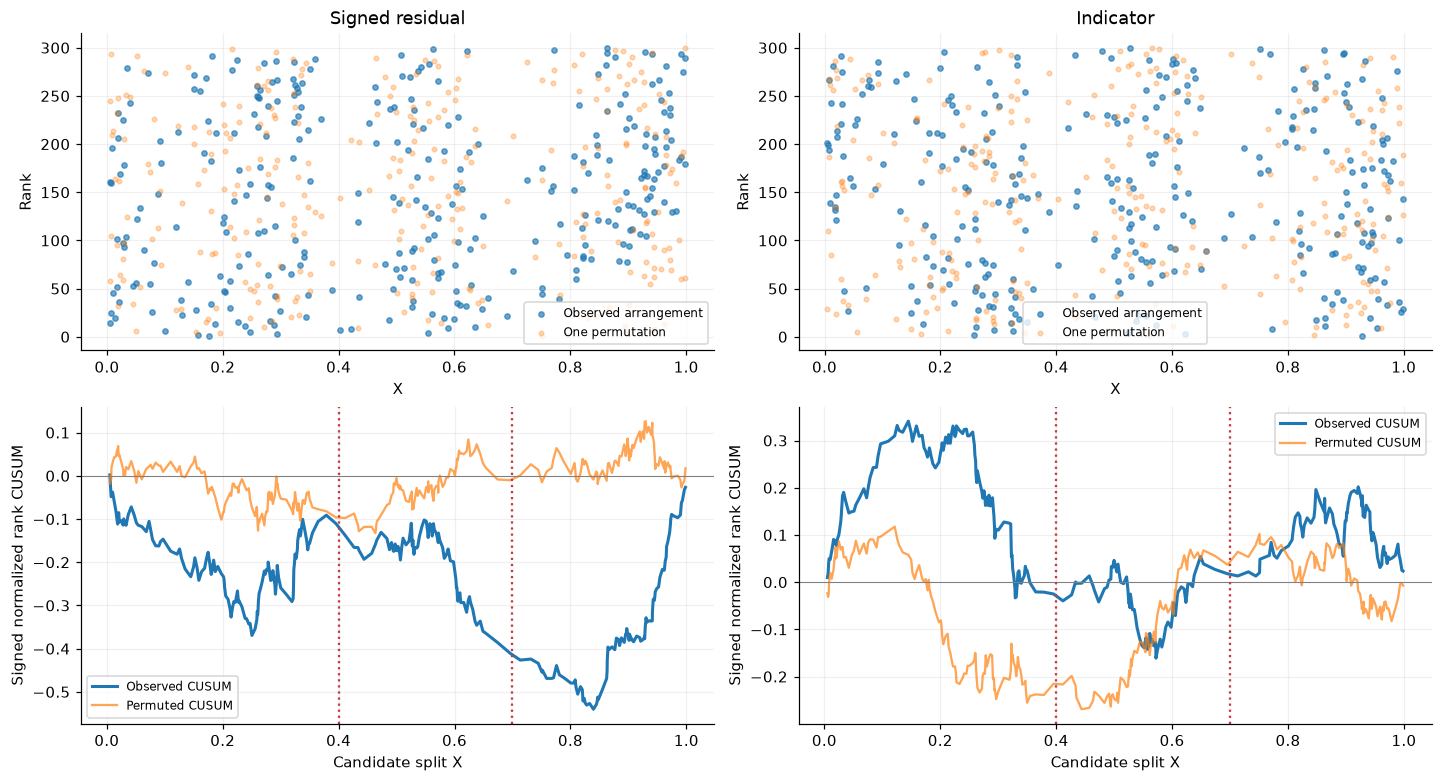

In [4]:
split_x = (data.X.to_numpy()[:-1] + data.X.to_numpy()[1:]) / 2
fig, axes = plt.subplots(2, 2, figsize=(13, 7), layout="constrained")
for col, name in enumerate(trial_columns):
    ax = axes[0, col]
    ax.scatter(data.X, ranks[name], s=12, alpha=0.65, label="Observed arrangement")
    ax.scatter(data.X, shuffled[name], s=9, alpha=0.3, label="One permutation")
    ax.set(title=name, ylabel="Rank", xlabel="X")
    ax.legend(fontsize=8)
    ax = axes[1, col]
    ax.plot(split_x, cusum(ranks[name]), lw=2, label="Observed CUSUM")
    ax.plot(split_x, cusum(shuffled[name]), alpha=0.7, label="Permuted CUSUM")
    ax.axhline(0, color="grey", lw=0.7)
    for k in model.breakpoints:
        ax.axvline(k, color="#C13D43", ls=":")
    ax.set(xlabel="Candidate split X", ylabel="Signed normalized rank CUSUM")
    ax.legend(fontsize=8)
plt.show()

## 3. Global and local permutation calibration

Under exchangeable tie-broken scores, the rank vector is a uniform permutation of $1,\ldots,n$. For each reference permutation, compute **all** the same interval statistics. This preserves dependence between overlapping windows. The two reported statistics are `Global` (full interval) and `Local max` (maximum over the entire family, including the global interval).

For either statistic, the paper's randomized p-value is
$$p_B=\frac{\#\{T^{(b)}>T_{obs}\}+U\,[1+\#\{T^{(b)}=T_{obs}\}]}{B+1},\quad U\sim U(0,1).$$
We also report the usual conservative $(1+\#\{T^{(b)}\ge T_{obs}\})/(B+1)$. Exactly uniform randomized p-values require the exchangeability assumptions; rank permutations alone do not prove those assumptions for a new score.

In [5]:
def p_values(observed, reference, rng):
    """Randomized ART p and conservative plus-one p, with numerical statistic ties."""
    equal = np.isclose(reference, observed, atol=1e-12, rtol=0)
    greater = (reference > observed) & ~equal
    randomized = (greater.sum() + rng.random() * (1 + equal.sum())) / (len(reference) + 1)
    conservative = (1 + greater.sum() + equal.sum()) / (len(reference) + 1)
    return randomized, conservative


rng_null = np.random.default_rng(SEED + 2)
permutations_null = np.stack([rng_null.permutation(np.arange(1, N + 1)) for _ in range(B)])
null_by_interval = scan_statistics(permutations_null, intervals)
reference = np.column_stack([null_by_interval[:, 0], null_by_interval.max(axis=1)])
observed_by_interval = {name: scan_statistics(r, intervals)[0] for name, r in ranks.items()}
rows = []
for name, values in observed_by_interval.items():
    for j, scope in enumerate(["Global", "Local max"]):
        observed = values[0] if j == 0 else values.max()
        p, p_plus = p_values(observed, reference[:, j], rng_null)
        rows.append(dict(score=name, scan=scope, statistic=observed,
                         p_randomized=p, p_conservative=p_plus,
                         reject_at_alpha=p < ALPHA))
results = pd.DataFrame(rows)
display(results)
print("These are trial permutation p-values, pending the null calibration study below.")

,score,scan,statistic,p_randomized,p_conservative,reject_at_alpha
0,Signed residual,Global,0.5402,0.0020,0.0020,True
1,Signed residual,Local max,0.7452,0.0003,0.0005,True
2,Indicator,Global,0.3410,0.1133,0.1135,False
3,Indicator,Local max,0.5030,0.0338,0.0345,True


These are trial permutation p-values, pending the null calibration study below.


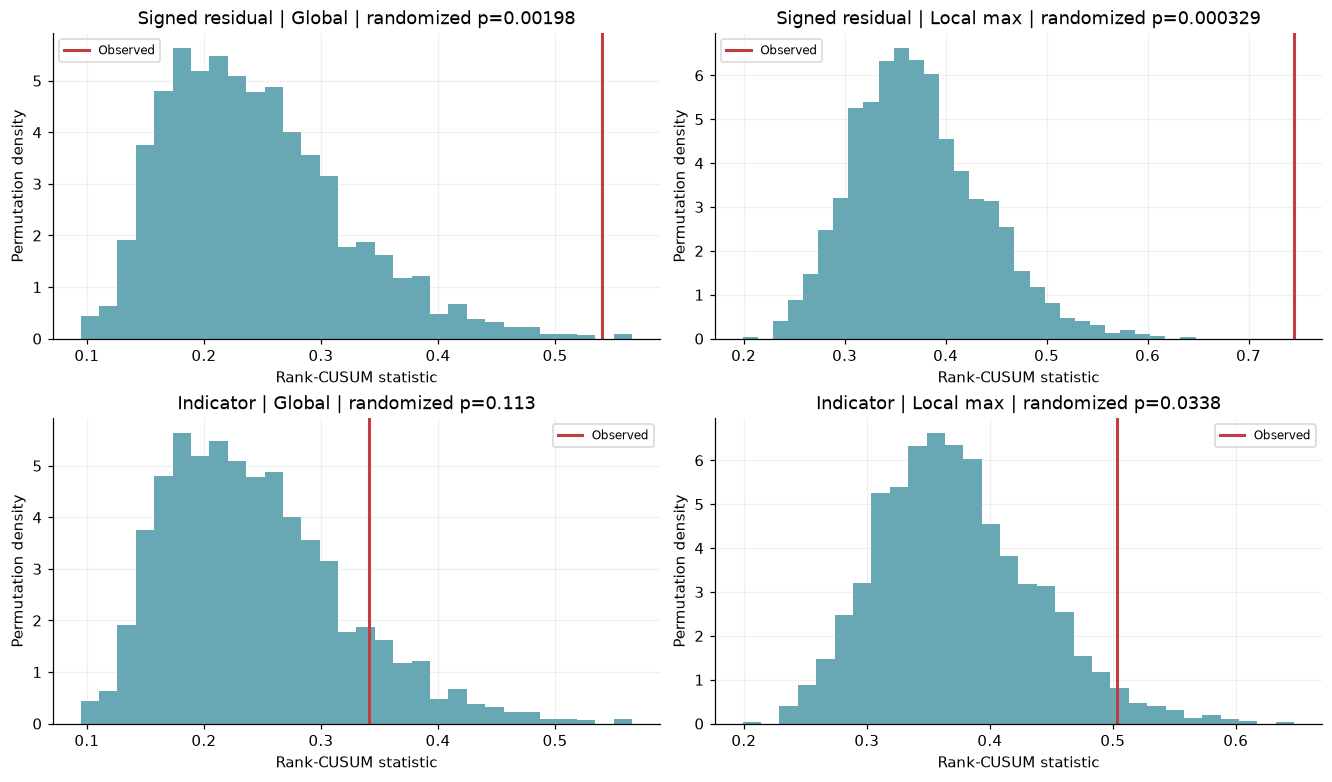

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for row, name in enumerate(trial_columns):
    for col, scope in enumerate(["Global", "Local max"]):
        ax = axes[row, col]
        ax.hist(reference[:, col], bins=30, color="#157A8C", alpha=0.65, density=True)
        record = results[(results.score == name) & (results.scan == scope)].iloc[0]
        ax.axvline(record.statistic, color="#C13D43", lw=2, label="Observed")
        ax.set(title=f"{name} | {scope} | randomized p={record.p_randomized:.3g}",
               xlabel="Rank-CUSUM statistic", ylabel="Permutation density")
        ax.legend(fontsize=8)
plt.show()

## 4. Inspect the local scans

Each candidate split is between two consecutive X order statistics; its plotted X coordinate is their midpoint. Windows were fixed using **indices only**. Under sparse sampling, their X widths differ. The table includes an unadjusted interval p-value and a conservative p-value adjusted by the **maximum across all intervals**.

An interval's CUSUM argmax is a location of score imbalance. It is an exploratory split, **not automatically a consistent slope-breakpoint estimate** or a confidence interval. In particular, no homogeneous-score model within linear segments is assumed here. Selecting the most interesting window for this plot does not turn its unadjusted p-value into a valid post-selection claim.

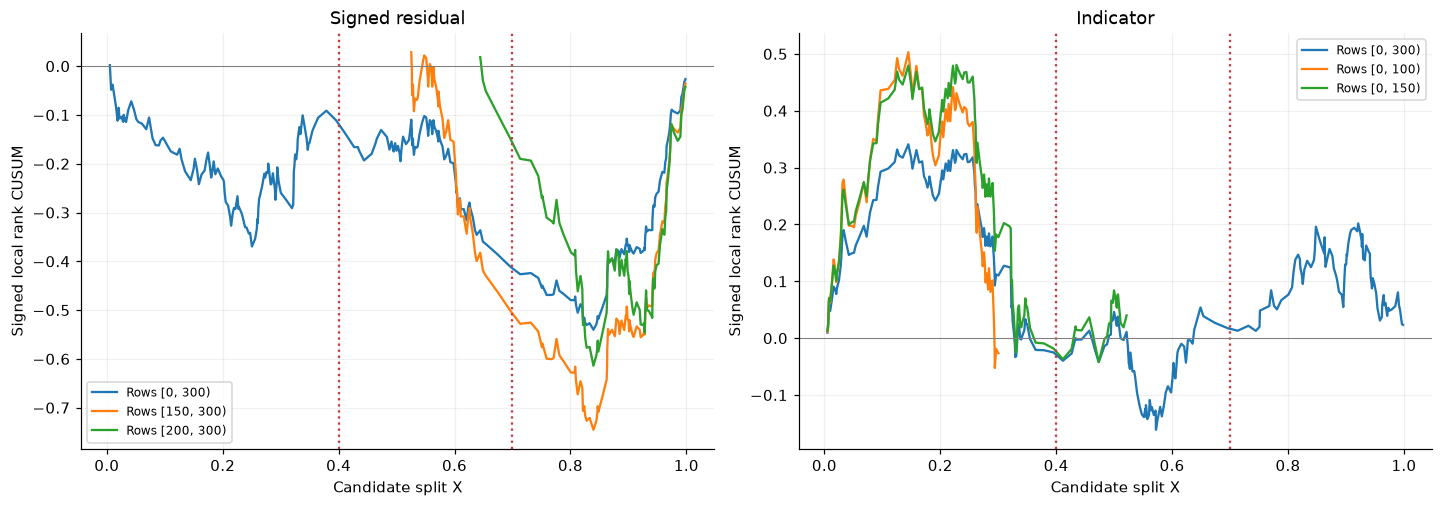

,score,start,stop,n_window,x_left,x_right,candidate_x,statistic,p_interval,p_max_adjusted
22,Indicator,0,100,100,0.0050,0.3017,0.1449,0.5030,0.0030,0.0345
19,Indicator,0,150,150,0.0050,0.5231,0.2278,0.4806,0.0075,0.0585
20,Indicator,75,225,150,0.2600,0.8211,0.5721,0.4657,0.0080,0.0835
32,Indicator,150,210,60,0.5245,0.7513,0.5721,0.3722,0.0470,0.4645
26,Indicator,200,300,100,0.6405,0.9988,0.9211,0.3440,0.0790,0.6470
3,Signed residual,150,300,150,0.5245,0.9988,0.8397,0.7452,0.0005,0.0005
8,Signed residual,200,300,100,0.6405,0.9988,0.8397,0.6140,0.0005,0.0010
0,Signed residual,0,300,300,0.0050,0.9988,0.8397,0.5402,0.0020,0.0145
17,Signed residual,240,300,60,0.8669,0.9988,0.9412,0.4755,0.0045,0.0670
2,Signed residual,75,225,150,0.2600,0.8211,0.5636,0.4387,0.0150,0.1615


In [7]:
local_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, (name, r) in zip(axes, ranks.items()):
    values = observed_by_interval[name]
    for j, (a, b) in enumerate(intervals):
        local = np.argsort(np.argsort(r[a:b])) + 1
        curve = cusum(local)
        t = np.abs(curve).argmax() + 1  # Number of observations to the left of this split.
        _, p_single = p_values(values[j], null_by_interval[:, j], rng_null)
        _, p_adjusted = p_values(values[j], reference[:, 1], rng_null)
        local_rows.append(dict(score=name, start=int(a), stop=int(b), n_window=b-a,
            x_left=data.X.iloc[a], x_right=data.X.iloc[b-1],
            candidate_x=(data.X.iloc[a+t-1] + data.X.iloc[a+t])/2,
            statistic=values[j], p_interval=p_single, p_max_adjusted=p_adjusted))
    # Display the full curve and the two strongest proper local windows.
    selected = [0, *(np.argsort(values[1:])[-2:][::-1] + 1)]
    for j in selected:
        a, b = intervals[j]
        local = np.argsort(np.argsort(r[a:b])) + 1
        ax.plot(split_x[a:b-1], cusum(local), label=f"Rows [{a}, {b})")
    for k in model.breakpoints:
        ax.axvline(k, color="#C13D43", ls=":")
    ax.axhline(0, color="grey", lw=0.7)
    ax.set(title=name, xlabel="Candidate split X", ylabel="Signed local rank CUSUM")
    ax.legend(fontsize=8)
plt.show()
local_results = pd.DataFrame(local_rows)
display(local_results.sort_values(["score", "statistic"], ascending=[True, False]).groupby("score").head(5))

## 5. Small exact checks of the rank algorithm

The shared chat's six-rank example has an exact nonrandomized permutation p-value of 0.10. We enumerate all 720 arrangements to check that result, check that batched local scans agree with direct reranking, and check that the quantile fit does not change when rows are shuffled.

In [8]:
toy = np.array([1, 2, 3, 6, 5, 4])
np.testing.assert_allclose(cusum(toy), np.array([-2.5, -4, -4.5, -2, -0.5]) / 6**1.5)
all_toy = np.array(list(permutations(range(1, 7))))
toy_reference = np.abs(cusum(all_toy)).max(axis=1)
toy_statistic = np.abs(cusum(toy)).max()
exact_p = np.mean(toy_reference >= toy_statistic - 1e-12)
assert np.isclose(exact_p, 0.10)
small_windows = np.array([(0, 6), (0, 4), (2, 6)])
slow = [[np.abs(cusum(np.argsort(np.argsort(r[a:b])) + 1)).max()
         for a, b in small_windows] for r in all_toy[:8]]
np.testing.assert_allclose(scan_statistics(all_toy[:8], small_windows), slow)
np.testing.assert_allclose(fit_quantile_line(data.sample(frac=1, random_state=42), TAU), coef)
assert all(np.array_equal(np.sort(r), np.arange(1, N+1)) for r in ranks.values())
print(f"Exact toy p={exact_p:.2f}; CUSUM, local reranking, and fit symmetry checks passed.")

Exact toy p=0.10; CUSUM, local reranking, and fit symmetry checks passed.


## 6. Do the trial p-values behave properly under no slope changes?

A straight conditional quantile does **not** imply identically distributed raw residuals across X. Our bounded model also changes shape on the response scale. Fitted indicators remove magnitude information, but estimating the line from the same sample introduces dependence and need not preserve exchangeability relative to X order.

We therefore compare the two requested fitted scores with **diagnostic benchmarks** using the known null line. Under the no-break null and a continuous response, $\mathbf1\{Y\le m_0(X)\}$ has probability $\tau$ at every X, so its independently generated indicator sequence remains i.i.d. Bernoulli after ordering by X. Randomized tie-breaking makes this a calibration check for the rank engine. Known-line residuals need not have that property.

For power, the known-line scores keep using the **straight null reference**, not the true bent curve. This is an oracle comparison unavailable in real data. We test global and local-max statistics for every score; the two tests and different scores are comparisons, not one jointly corrected decision.

The rank reference bank is reused to keep the notebook fast. Thus reported Monte Carlo intervals condition on that finite bank; its own simulation error is not included. Increase `B` and `REPLICATIONS` for a larger study.

In [9]:
score_columns = {
    "Residual / fitted": "residual_fitted",
    "Indicator / fitted": "indicator_fitted",
    "Residual / known null": "residual_known",
    "Indicator / known null": "indicator_known",
}
scenarios = {"H0: no slope changes": replace(model, slope_changes=(0.0,) * len(model.breakpoints)),
             "H1: two slope changes": model}
rng_mc = np.random.default_rng(SEED + 3)
mc_rows = []
for scenario, dgp in scenarios.items():
    for rep in range(REPLICATIONS):
        generated = dgp.generate(seed=int(rng_mc.integers(0, 2**32)))
        scored, _ = score_data(generated, TAU)
        for name, column in score_columns.items():
            r = random_ranks(scored[column], rng_mc)
            values = scan_statistics(r, intervals)[0]
            for j, scope in enumerate(["Global", "Local max"]):
                observed = values[0] if j == 0 else values.max()
                p, _ = p_values(observed, reference[:, j], rng_mc)
                mc_rows.append(dict(scenario=scenario, replication=rep, score=name,
                                    scan=scope, statistic=observed, p_value=p))
    print(f"Completed {REPLICATIONS} independently generated datasets: {scenario}")
pvalue_results = pd.DataFrame(mc_rows)
summary_rows = []
for (scenario, name, scope), group in pvalue_results.groupby(["scenario", "score", "scan"], sort=False):
    k, count = int((group.p_value < ALPHA).sum()), len(group)
    ci = binomtest(k, count).proportion_ci(confidence_level=0.95, method="wilson")
    summary_rows.append(dict(scenario=scenario, score=name, scan=scope,
        replications=count, rejection_rate=k/count, ci_low=ci.low, ci_high=ci.high))
rejection_summary = pd.DataFrame(summary_rows)
display(rejection_summary)
print(f"Nominal alpha={ALPHA}; nominal binomial MC s.e. is about {np.sqrt(ALPHA*(1-ALPHA)/REPLICATIONS):.3f}.")

Completed 300 independently generated datasets: H0: no slope changes


Completed 300 independently generated datasets: H1: two slope changes


,scenario,score,scan,replications,rejection_rate,ci_low,ci_high
0,H0: no slope changes,Residual / fitted,Global,300,0.2633,0.2167,0.3159
1,H0: no slope changes,Residual / fitted,Local max,300,0.1367,0.1024,0.1802
2,H0: no slope changes,Indicator / fitted,Global,300,0.0100,0.0034,0.0290
3,H0: no slope changes,Indicator / fitted,Local max,300,0.0500,0.0305,0.0808
4,H0: no slope changes,Residual / known null,Global,300,0.2467,0.2013,0.2984
5,H0: no slope changes,Residual / known null,Local max,300,0.1267,0.0937,0.1691
6,H0: no slope changes,Indicator / known null,Global,300,0.0400,0.0230,0.0686
7,H0: no slope changes,Indicator / known null,Local max,300,0.0300,0.0159,0.0560
8,H1: two slope changes,Residual / fitted,Global,300,0.7233,0.6701,0.7709
9,H1: two slope changes,Residual / fitted,Local max,300,0.9633,0.9355,0.9794


Nominal alpha=0.05; nominal binomial MC s.e. is about 0.013.


The plots below are empirical CDFs of **p-values**, not score distributions. Under calibration, the no-break curve should track the diagonal. A no-break curve above the diagonal near 0.05 signals excess false rejections; a large power under that condition cannot establish a useful test. The bent-model curve should move toward small p-values if the score has power.

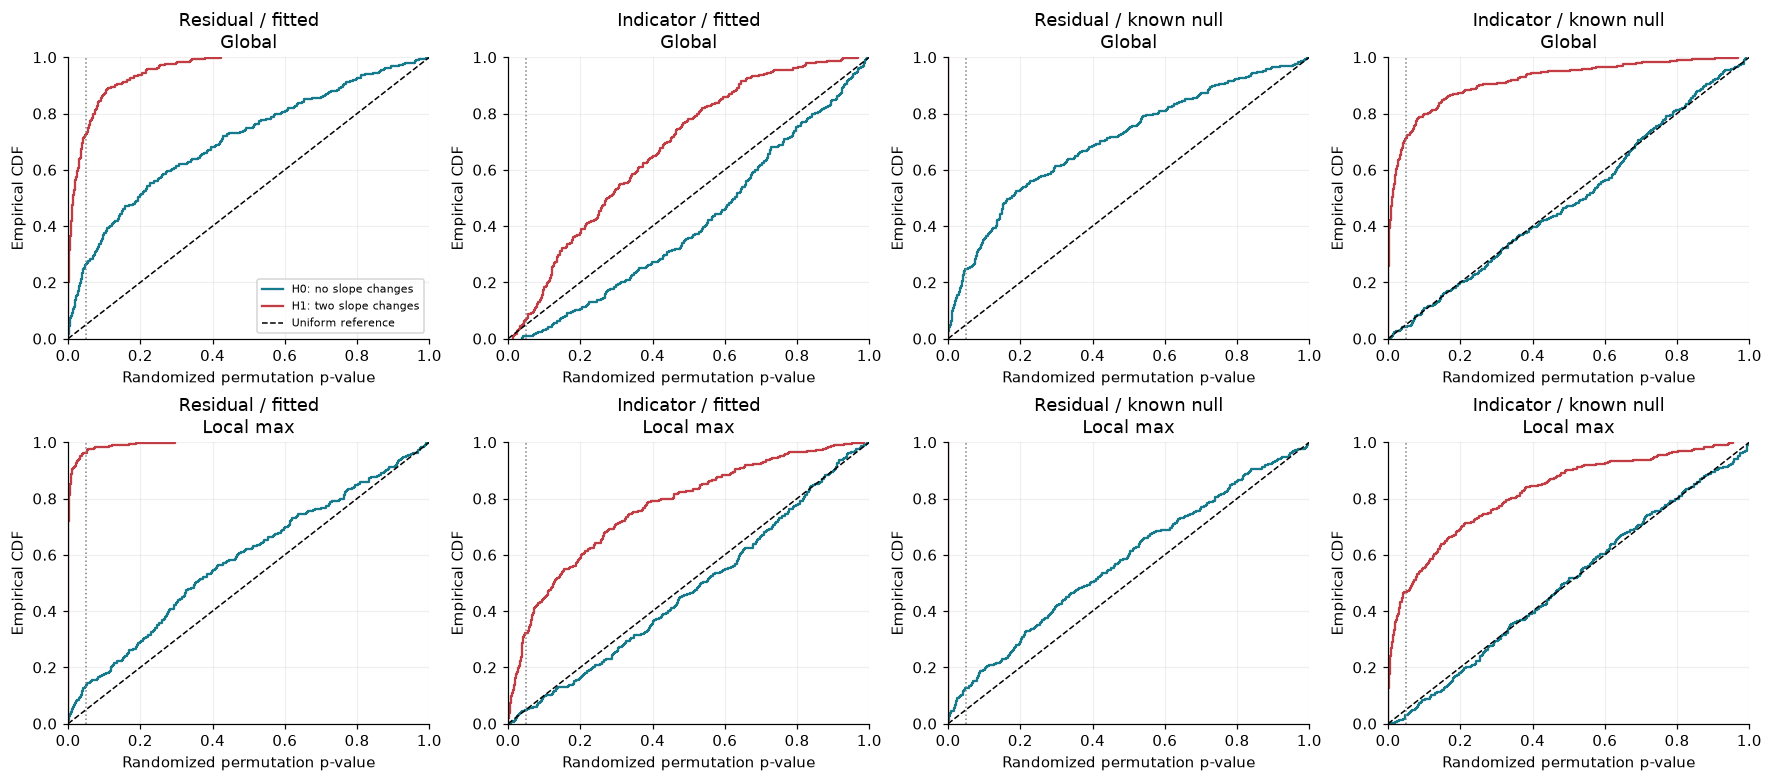

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout="constrained")
colors = {"H0: no slope changes": "#157A8C", "H1: two slope changes": "#C13D43"}
for col, name in enumerate(score_columns):
    for row, scope in enumerate(["Global", "Local max"]):
        ax = axes[row, col]
        for scenario, color in colors.items():
            values = np.sort(pvalue_results.loc[(pvalue_results.score == name) &
                (pvalue_results.scan == scope) & (pvalue_results.scenario == scenario), "p_value"])
            ax.step(values, np.arange(1, len(values)+1)/len(values), where="post", color=color, label=scenario)
        ax.plot([0, 1], [0, 1], "k--", lw=1, label="Uniform reference")
        ax.axvline(ALPHA, color="grey", ls=":", lw=1)
        ax.set(title=f"{name}\n{scope}", xlabel="Randomized permutation p-value", ylabel="Empirical CDF",
               xlim=(0, 1), ylim=(0, 1))
        if row == 0 and col == 0:
            ax.legend(fontsize=7)
plt.show()

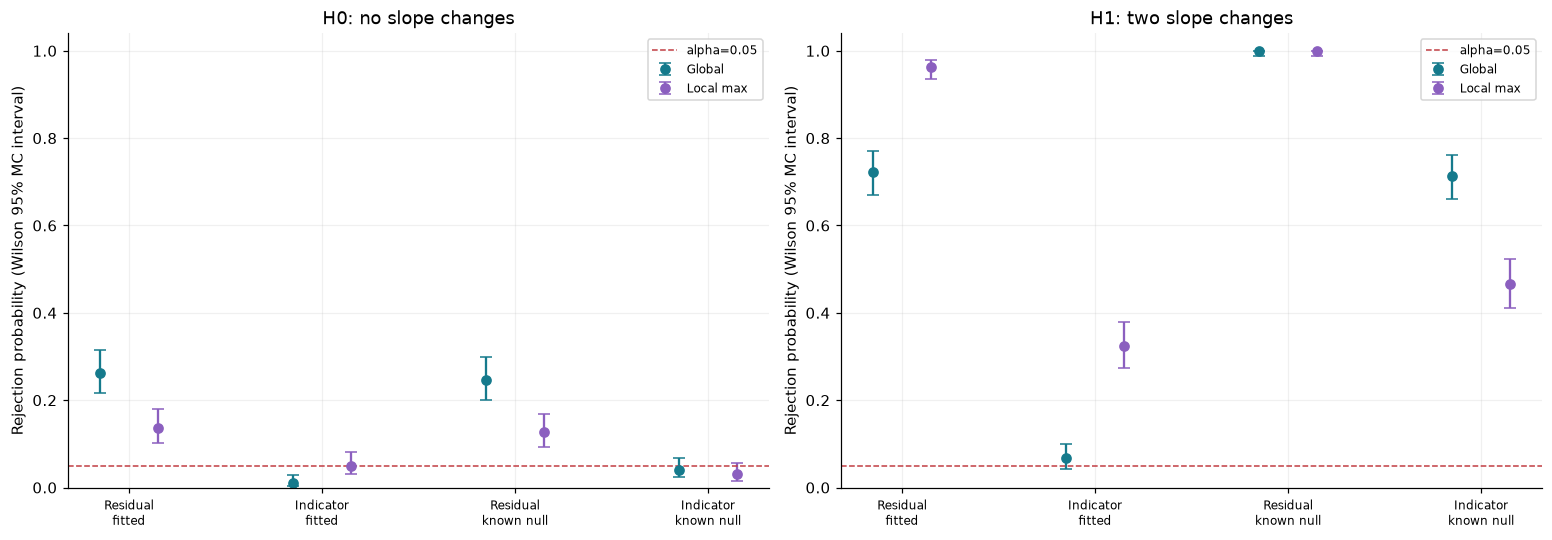

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout="constrained")
positions = np.arange(len(score_columns))
for ax, scenario in zip(axes, scenarios):
    for offset, scope, color in [(-0.15, "Global", "#157A8C"), (0.15, "Local max", "#8b5fbf")]:
        table = rejection_summary[(rejection_summary.scenario == scenario) &
            (rejection_summary.scan == scope)].set_index("score").loc[list(score_columns)]
        ax.errorbar(positions+offset, table.rejection_rate,
            yerr=np.vstack([table.rejection_rate-table.ci_low, table.ci_high-table.rejection_rate]),
            fmt="o", color=color, capsize=4, label=scope)
    ax.axhline(ALPHA, color="#C13D43", ls="--", lw=1, label=f"alpha={ALPHA}")
    ax.set_xticks(positions, [name.replace(" / ", "\n") for name in score_columns], fontsize=8)
    ax.set(title=scenario, ylabel="Rejection probability (Wilson 95% MC interval)", ylim=(0, 1.04))
    ax.legend(fontsize=8)
plt.show()

# Optional exports: every observation and every Monte Carlo p-value remain available.
# data.to_csv("art_example_data.csv", index=False)
# results.to_csv("art_example_tests.csv", index=False)
# local_results.to_csv("art_local_scans.csv", index=False)
# pvalue_results.to_csv("art_pvalue_simulations.csv", index=False)

In [12]:
# Compact comparison: read false-rejection rates before interpreting power.
comparison = rejection_summary.pivot(index=["score", "scan"], columns="scenario", values="rejection_rate")
display(comparison.rename(columns={"H0: no slope changes": "Null rejection rate",
                                   "H1: two slope changes": "Alternative rejection rate"}))
for name in ["Residual / fitted", "Indicator / fitted"]:
    rows = rejection_summary[(rejection_summary.score == name) &
                             (rejection_summary.scenario == "H0: no slope changes")]
    for row in rows.itertuples():
        status = "above nominal" if row.ci_low > ALPHA else ("below nominal" if row.ci_high < ALPHA else "compatible with nominal")
        print(f"{name}, {row.scan}: null rejection {row.rejection_rate:.1%}; Wilson interval is {status} {ALPHA:.0%}.")
print("Compatibility at one alpha and one simulation setting is not a proof of exchangeability.")

scenario                          Null rejection rate  \
score                  scan                             
Indicator / fitted     Global                  0.0100   
                       Local max               0.0500   
Indicator / known null Global                  0.0400   
                       Local max               0.0300   
Residual / fitted      Global                  0.2633   
                       Local max               0.1367   
Residual / known null  Global                  0.2467   
                       Local max               0.1267   

scenario                          Alternative rejection rate  
score                  scan                                   
Indicator / fitted     Global                         0.0667  
                       Local max                      0.3233  
Indicator / known null Global                         0.7133  
                       Local max                      0.4667  
Residual / fitted      Global                         0.7233  
                       Local max                      0.9633  
Residual / known null  Global                         1.0000  
                       Local max                      1.0000

Residual / fitted, Global: null rejection 26.3%; Wilson interval is above nominal 5%.
Residual / fitted, Local max: null rejection 13.7%; Wilson interval is above nominal 5%.
Indicator / fitted, Global: null rejection 1.0%; Wilson interval is below nominal 5%.
Indicator / fitted, Local max: null rejection 5.0%; Wilson interval is compatible with nominal 5%.
Compatibility at one alpha and one simulation setting is not a proof of exchangeability.


## Reading the experiment

1. Start with the **known-null indicator under H0**. Its approximately uniform p-values are a check that ranking, random ties, local reranking, and joint permutation calibration work together.
2. Compare **fitted indicators** with that benchmark. Any loss of calibration belongs to the proposed fitted-score extension and must be addressed before claiming exact quantile-breakpoint inference.
3. Compare signed residuals with indicators. Residuals retain magnitude information but may detect heteroskedastic or bounded-response effects even without slope changes.
4. Compare global with local max using their separately calibrated references. A local maximum can help with multiple patterns, but scanning adds a multiplicity cost and cannot repair an unsuitable score.

These settings form a pilot study, not a conclusion that either fitted score is valid. All source data and numerical results are available as `data`, `results`, `local_results`, `pvalue_results`, and `rejection_summary`. Change the configuration cell to explore sample size, slope changes, scale, and sparsity, then rerun all cells. The stored execution uses the globally registered **Course Python** kernel.